<a href="https://colab.research.google.com/github/danushkumar77/Hospital-Appointment-Insight/blob/main/CareBridge_Round2_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

# Generate appointment data
appointments = pd.DataFrame({
    "appointment_id": [f"A{i:04d}" for i in range(1, n+1)],
    "patient_id": np.random.choice(
        [f"P{i:03d}" for i in range(1, 301)], n
    ),
    "appointment_date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2026-01-01", "2026-09-30"),
            n
        )
    ),
    "department": np.random.choice(
        ["Cardiology", "Dermatology",
         "General Medicine", "Orthopedics",
         "Pediatrics", "ENT"], n
    ),
    "status": np.random.choice(
        ["Attended", "No-show", "Cancelled", None],
        n,
        p=[0.68, 0.18, 0.10, 0.04]
    ),
    "waiting_days": np.random.randint(0, 31, n)
})

# Create patient data
patients = pd.DataFrame({
    "patient_id": [f"P{i:03d}" for i in range(1, 301)],
    "age_group": np.random.choice(
        ["18-29", "30-44", "45-59", "60+"], 300
    ),
    "locality": np.random.choice(
        ["North", "South", "East", "West", "Rural"], 300
    ),
    "visit_history": np.random.choice(
        ["New Patient", "1-2 Visits",
         "3-5 Visits", "6+ Visits"], 300
    )
})

# Create doctor data
doctors = pd.DataFrame({
    "doctor_id": [f"D{i:03d}" for i in range(1, 31)],
    "specialty": np.random.choice(
        ["Cardiology", "Dermatology",
         "General Medicine", "Orthopedics",
         "Pediatrics", "ENT"], 30
    ),
    "clinic_schedule": np.random.choice(
        ["Morning", "Afternoon", "Evening"], 30
    )
})

# Create reminder data
reminders = pd.DataFrame({
    "appointment_id": appointments["appointment_id"],
    "reminder_type": np.random.choice(
        ["SMS", "WhatsApp", "Phone Call", "Email",
         "No Reminder"], n
    ),
    "sent_status": np.random.choice(
        ["Sent", "Failed", "Not Applicable"], n
    ),
    "response": np.random.choice(
        ["Confirmed", "Rescheduled", "No Response"], n
    )
})

# Create calendar data
calendar = pd.DataFrame({
    "appointment_date": pd.date_range(
        "2026-01-01", "2026-09-30"
    )
})

calendar["weekday"] = calendar["appointment_date"].dt.day_name()
calendar["holiday"] = np.where(
    calendar["appointment_date"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)
calendar["season"] = calendar["appointment_date"].dt.month.map(
    lambda m: "Winter" if m in [1, 2]
    else "Summer" if m in [3, 4, 5]
    else "Monsoon" if m in [6, 7, 8, 9]
    else "Post-Monsoon"
)

print("Synthetic datasets created successfully!")
print("Appointments:", appointments.shape)
print("Patients:", patients.shape)
print("Doctors:", doctors.shape)
print("Reminders:", reminders.shape)
print("Calendar:", calendar.shape)

Synthetic datasets created successfully!
Appointments: (1000, 6)
Patients: (300, 4)
Doctors: (30, 3)
Reminders: (1000, 4)
Calendar: (273, 4)


In [2]:
from google.colab import files
import zipfile
import os

os.makedirs("carebridge_data", exist_ok=True)

datasets = {
    "appointments.csv": appointments,
    "patients.csv": patients,
    "doctors.csv": doctors,
    "reminders.csv": reminders,
    "calendar.csv": calendar
}

for filename, df in datasets.items():
    df.to_csv(f"carebridge_data/{filename}", index=False)

with zipfile.ZipFile(
    "CareBridge_Synthetic_Data.zip", "w"
) as z:
    for filename in datasets:
        z.write(f"carebridge_data/{filename}", filename)

files.download("CareBridge_Synthetic_Data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
print(appointments.head())
print(appointments.shape)
print(appointments.info())
print(appointments.describe(include="all"))

  appointment_id patient_id appointment_date   department    status  \
0          A0001       P103       2026-05-24   Pediatrics  Attended   
1          A0002       P271       2026-01-19          ENT  Attended   
2          A0003       P107       2026-01-18          ENT  Attended   
3          A0004       P072       2026-09-14  Dermatology  Attended   
4          A0005       P189       2026-03-19          ENT  Attended   

   waiting_days  
0            11  
1            21  
2            21  
3            17  
4            14  
(1000, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   appointment_id    1000 non-null   object        
 1   patient_id        1000 non-null   object        
 2   appointment_date  1000 non-null   datetime64[ns]
 3   department        1000 non-null   object        
 4   status            961

In [4]:
print("Missing values:")
print(appointments.isnull().sum())

print("Duplicate rows:", appointments.duplicated().sum())

print("Appointment statuses:")
print(appointments["status"].value_counts(dropna=False))

print("Department names:")
print(appointments["department"].unique())

print("Waiting days:")
print(appointments["waiting_days"].describe())

Missing values:
appointment_id       0
patient_id           0
appointment_date     0
department           0
status              39
waiting_days         0
dtype: int64
Duplicate rows: 0
Appointment statuses:
status
Attended     671
No-show      197
Cancelled     93
None          39
Name: count, dtype: int64
Department names:
['Pediatrics' 'ENT' 'Dermatology' 'Orthopedics' 'Cardiology'
 'General Medicine']
Waiting days:
count    1000.000000
mean       15.659000
std         8.704855
min         0.000000
25%         8.000000
50%        16.000000
75%        23.000000
max        30.000000
Name: waiting_days, dtype: float64


In [5]:
cleaned = appointments.copy()

# Remove exact duplicate rows
cleaned = cleaned.drop_duplicates()

# Standardize department names
cleaned["department"] = (
    cleaned["department"].str.strip().str.title()
)

# Keep missing status as unknown
cleaned["status"] = cleaned["status"].fillna("Unknown")

# Flag invalid waiting days rather than silently changing them
cleaned["invalid_waiting_days"] = (
    (cleaned["waiting_days"] < 0) |
    (cleaned["waiting_days"] > 90)
)

print(cleaned.head())

  appointment_id patient_id appointment_date   department    status  \
0          A0001       P103       2026-05-24   Pediatrics  Attended   
1          A0002       P271       2026-01-19          Ent  Attended   
2          A0003       P107       2026-01-18          Ent  Attended   
3          A0004       P072       2026-09-14  Dermatology  Attended   
4          A0005       P189       2026-03-19          Ent  Attended   

   waiting_days  invalid_waiting_days  
0            11                 False  
1            21                 False  
2            21                 False  
3            17                 False  
4            14                 False  


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

Which departments have more missed appointments?

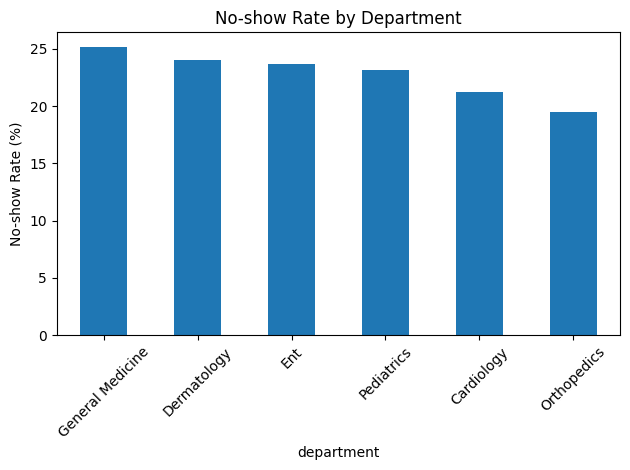

In [7]:
eligible = cleaned[
    cleaned["status"].isin(["Attended", "No-show"])
]

dept_rate = (
    eligible.assign(
        no_show=(eligible["status"] == "No-show")
    )
    .groupby("department")["no_show"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

dept_rate.plot(kind="bar")
plt.title("No-show Rate by Department")
plt.ylabel("No-show Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Does waiting time affect attendance?

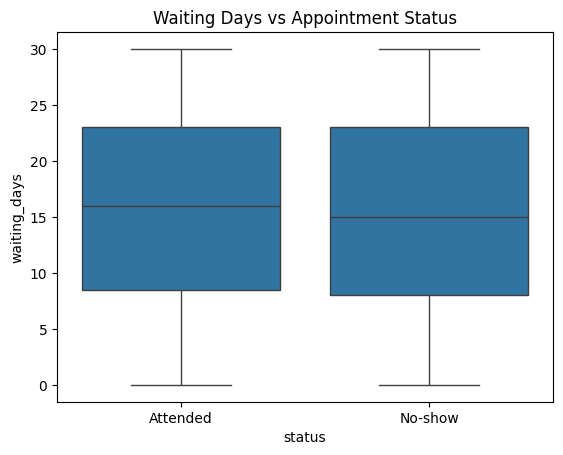

In [8]:
sns.boxplot(
    data=eligible,
    x="status",
    y="waiting_days"
)
plt.title("Waiting Days vs Appointment Status")
plt.show()

Which weekdays have higher no-show rates?

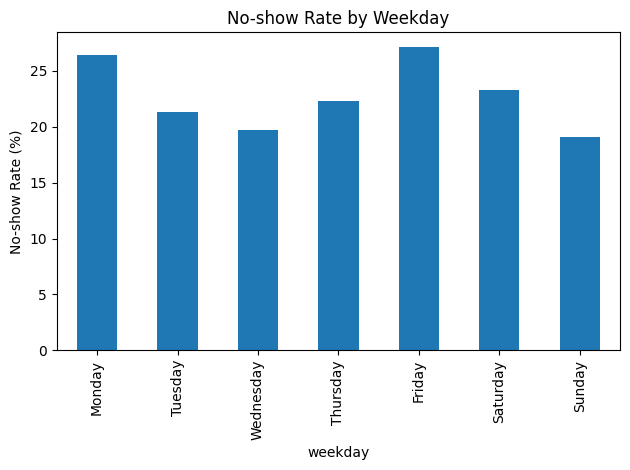

In [9]:
cleaned["weekday"] = (
    pd.to_datetime(cleaned["appointment_date"]).dt.day_name()
)

eligible = cleaned[
    cleaned["status"].isin(["Attended", "No-show"])
].copy()

weekday_rate = (
    eligible.assign(
        no_show=(eligible["status"] == "No-show")
    )
    .groupby("weekday")["no_show"]
    .mean()
    .mul(100)
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

weekday_rate.plot(kind="bar")
plt.title("No-show Rate by Weekday")
plt.ylabel("No-show Rate (%)")
plt.tight_layout()
plt.show()

In [10]:
analysis_df = cleaned.merge(
    patients, on="patient_id", how="left"
)

analysis_df = analysis_df.merge(
    reminders.drop_duplicates("appointment_id"),
    on="appointment_id",
    how="left"
)

analysis_df = analysis_df.merge(
    calendar,
    on="appointment_date",
    how="left"
)

print(analysis_df.shape)
print(analysis_df.head())

(1000, 17)
  appointment_id patient_id appointment_date   department    status  \
0          A0001       P103       2026-05-24   Pediatrics  Attended   
1          A0002       P271       2026-01-19          Ent  Attended   
2          A0003       P107       2026-01-18          Ent  Attended   
3          A0004       P072       2026-09-14  Dermatology  Attended   
4          A0005       P189       2026-03-19          Ent  Attended   

   waiting_days  invalid_waiting_days weekday_x age_group locality  \
0            11                 False    Sunday       60+     East   
1            21                 False    Monday     18-29    South   
2            21                 False    Sunday     45-59    South   
3            17                 False    Monday     45-59    Rural   
4            14                 False  Thursday       60+    South   

  visit_history reminder_type     sent_status     response weekday_y  holiday  \
0     6+ Visits           SMS          Failed  Rescheduled  

In [11]:
analysis_df["is_no_show"] = (
    analysis_df["status"] == "No-show"
).astype(int)

analysis_df["appointment_month"] = (
    pd.to_datetime(analysis_df["appointment_date"]).dt.month
)

analysis_df["is_long_wait"] = (
    analysis_df["waiting_days"] >= 7
).astype(int)

analysis_df["is_new_patient"] = (
    analysis_df["visit_history"] == "New Patient"
).astype(int)

print(analysis_df[
    ["status", "is_no_show", "appointment_month",
     "is_long_wait", "is_new_patient"]
].head())

     status  is_no_show  appointment_month  is_long_wait  is_new_patient
0  Attended           0                  5             1               0
1  Attended           0                  1             1               1
2  Attended           0                  1             1               0
3  Attended           0                  9             1               0
4  Attended           0                  3             1               0


In [12]:
model_df = analysis_df[
    analysis_df["status"].isin(["Attended", "No-show"])
].copy()

model_df = pd.get_dummies(
    model_df,
    columns=["department", "age_group", "locality"],
    dtype=int
)

print(model_df.head())

  appointment_id patient_id appointment_date    status  waiting_days  \
0          A0001       P103       2026-05-24  Attended            11   
1          A0002       P271       2026-01-19  Attended            21   
2          A0003       P107       2026-01-18  Attended            21   
3          A0004       P072       2026-09-14  Attended            17   
4          A0005       P189       2026-03-19  Attended            14   

   invalid_waiting_days weekday_x visit_history reminder_type     sent_status  \
0                 False    Sunday     6+ Visits           SMS          Failed   
1                 False    Monday   New Patient   No Reminder  Not Applicable   
2                 False    Sunday    1-2 Visits    Phone Call  Not Applicable   
3                 False    Monday    1-2 Visits    Phone Call  Not Applicable   
4                 False  Thursday    1-2 Visits   No Reminder            Sent   

   ... department_Pediatrics age_group_18-29 age_group_30-44 age_group_45-59  \


In [13]:
analysis_df.to_csv(
    "CareBridge_Cleaned_Analysis.csv", index=False
)

files.download("CareBridge_Cleaned_Analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Keep only known attendance outcomes
ml_df = analysis_df[
    analysis_df["status"].isin(["Attended", "No-show"])
].copy()

# Target: 1 = No-show, 0 = Attended
ml_df["is_no_show"] = (
    ml_df["status"] == "No-show"
).astype(int)

# Input features
features = [
    "waiting_days",
    "department",
    "age_group",
    "locality",
    "visit_history",
    "reminder_type",
    "weekday",
    "appointment_month"
]

X = ml_df[features]
y = ml_df["is_no_show"]

print("Input shape:", X.shape)
print("Target distribution:")
print(y.value_counts())
print("\nNo-show percentage:", round(y.mean() * 100, 2), "%")

KeyError: "['weekday'] not in index"

In [15]:
# Convert appointment_date to datetime
analysis_df["appointment_date"] = pd.to_datetime(
    analysis_df["appointment_date"]
)

# Create weekday from appointment_date
analysis_df["weekday"] = (
    analysis_df["appointment_date"].dt.day_name()
)

# Create appointment_month if it is also missing
analysis_df["appointment_month"] = (
    analysis_df["appointment_date"].dt.month
)

print(analysis_df.columns.tolist())

['appointment_id', 'patient_id', 'appointment_date', 'department', 'status', 'waiting_days', 'invalid_waiting_days', 'weekday_x', 'age_group', 'locality', 'visit_history', 'reminder_type', 'sent_status', 'response', 'weekday_y', 'holiday', 'season', 'is_no_show', 'appointment_month', 'is_long_wait', 'is_new_patient', 'weekday']


In [16]:
ml_df = analysis_df[
    analysis_df["status"].isin(["Attended", "No-show"])
].copy()

ml_df["is_no_show"] = (
    ml_df["status"] == "No-show"
).astype(int)

features = [
    "waiting_days",
    "department",
    "age_group",
    "locality",
    "visit_history",
    "reminder_type",
    "weekday",
    "appointment_month"
]

# Check for missing feature columns
missing = [col for col in features if col not in ml_df.columns]
print("Missing columns:", missing)

X = ml_df[features]
y = ml_df["is_no_show"]

print("Input shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

Missing columns: []
Input shape: (868, 8)
Target distribution:
is_no_show
0    671
1    197
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 694
Testing records: 174


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

numeric_features = ["waiting_days", "appointment_month"]

categorical_features = [
    "department",
    "age_group",
    "locality",
    "visit_history",
    "reminder_type",
    "weekday"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, y_pred, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Attended", "No-show"],
    zero_division=0
))

Accuracy: 0.7701
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Confusion Matrix:
[[134   1]
 [ 39   0]]

Classification Report:
              precision    recall  f1-score   support

    Attended       0.77      0.99      0.87       135
     No-show       0.00      0.00      0.00        39

    accuracy                           0.77       174
   macro avg       0.39      0.50      0.44       174
weighted avg       0.60      0.77      0.68       174



                                   feature  importance
0                    numeric__waiting_days    0.162643
1               numeric__appointment_month    0.118429
17   categorical__visit_history_1-2 Visits    0.028626
14             categorical__locality_Rural    0.027304
20  categorical__visit_history_New Patient    0.026422
25     categorical__reminder_type_WhatsApp    0.025650
8             categorical__age_group_18-29    0.025295
6      categorical__department_Orthopedics    0.024732
12              categorical__locality_East    0.024633
9             categorical__age_group_30-44    0.024454


<Axes: title={'center': 'Top 10 Feature Importances'}, ylabel='feature'>

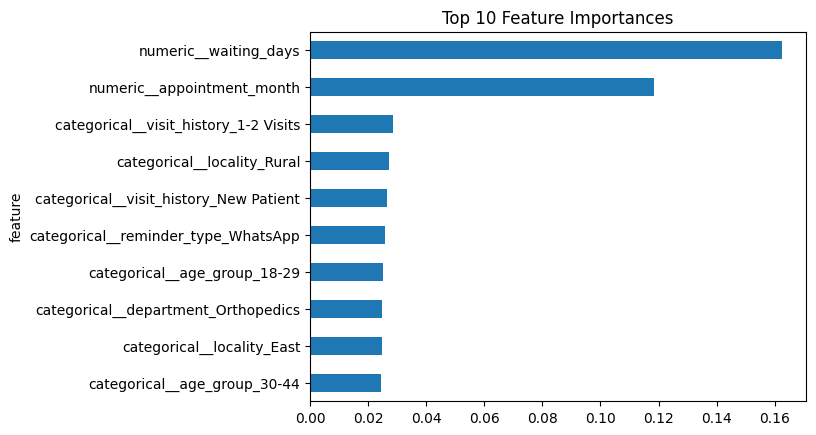

In [20]:
import pandas as pd

feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importance
}).sort_values("importance", ascending=False)

print(importance_df.head(10))

importance_df.head(10).sort_values(
    "importance"
).plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False,
    title="Top 10 Feature Importances"
)

In [21]:
import joblib

joblib.dump(model, "carebridge_random_forest.pkl")

ml_df.to_csv(
    "CareBridge_ML_Dataset.csv",
    index=False
)

print("Dataset and trained model saved.")

Dataset and trained model saved.


In [22]:
from google.colab import files

files.download("CareBridge_ML_Dataset.csv")
files.download("carebridge_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>